# Ejercicio 12.3 — Análisis de accesibilidad: auditoría real, formularios A/B y experimento solo teclado

**Curso:** IHC — Interacción Hombre-Computador (202W0606) · UNMSM · 2026-II · **Semana 12 (Unidad IV)**
**Tema:** Accesibilidad y diseño universal · WCAG 2.2 · comprobación de la accesibilidad · **RA4**

Este cuaderno analiza **tres fuentes** (guía de estilo v5, §4.6):

| Parte | Archivo | Origen |
|-------|---------|--------|
| A | `auditoria_accesibilidad_axe_sitios_reales.csv` y `auditoria_accesibilidad_axe_detalle_reglas.csv` | **Fuente B**: ejecución real de **axe-core 4.10.2** sobre 14 sitios públicos (URL, fecha y hora en el propio CSV) |
| B | `ejercicio_12_2_verificador_resultados.csv` (exportado por el verificador 12.2) | **Fuente A**: comprobaciones reales sobre el DOM de los formularios A y B |
| C | `ejercicio_12_3_experimento_teclado.csv` (exportado por el experimento 12.3) | **Fuente D**: **participantes de su clase** (código anónimo, con consentimiento) |

> **Límites declarados.** Las pruebas automáticas detectan solo una parte de los problemas (orden de ≈ 30–40 %); no son un veredicto de conformidad WCAG. Con **14 sitios** (7 + 7) las comparaciones Perú frente a internacional son **descriptivas, no inferenciales**. Los archivos `*_PRUEBA_TECNICA_BOT.csv` son una prueba técnica del *pipeline*: **no se interpretan**. Si falta un CSV de su clase, el cuaderno **no inventa datos**: avisa y continúa.

In [1]:
# =========================================================
# Celda 1 — Librerías, estilo y carga de archivos / Libraries, style and file loading
# Entorno de ejecución: Google Colaboratory (Colab) · CPU
# =========================================================
import os, math                           # utilidades estándar / standard utilities
import pandas as pd                       # tablas / tables
import numpy as np                        # cálculo numérico / numeric computing
import matplotlib.pyplot as plt           # gráficos / charts

PALETA = ["#1F3864", "#800000", "#1B7E34", "#C5961A", "#5B2C6F", "#0A3D5C"]   # paleta del curso
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#333333", "axes.grid": True,
                     "grid.color": "#DDDDDD", "axes.prop_cycle": plt.cycler(color=PALETA), "font.size": 11})

# En Colab, si los CSV no están en la carpeta actual, se pueden subir con este bloque (se ignora fuera de Colab)
ARCHIVOS = ["auditoria_accesibilidad_axe_sitios_reales.csv", "auditoria_accesibilidad_axe_detalle_reglas.csv"]
try:
    from google.colab import files        # solo existe en Colab / only exists in Colab
    faltan = [a for a in ARCHIVOS if not os.path.exists(a)]
    if faltan:
        print("Suba estos archivos:", faltan); files.upload()
except ImportError:
    pass
print("pandas", pd.__version__, "· numpy", np.__version__)

pandas 2.2.3 · numpy 1.26.4


## 1. Fórmulas del tema (regla de los 3 formatos + lectura verbal)

**Luminancia relativa de un color sRGB (WCAG 2.2)**

- **Formato Markdown:** `L = 0,2126·R + 0,7152·G + 0,0722·B`, con cada canal c linealizado: `c = c_sRGB/12,92` si `c_sRGB ≤ 0,04045`; si no, `((c_sRGB + 0,055)/1,055)^2,4`.
- **Formato LaTeX:** `L = 0{,}2126\,R + 0{,}7152\,G + 0{,}0722\,B`
- **Formato texto:** La luminancia es cero coma dos uno dos seis por rojo, más cero coma siete uno cinco dos por verde, más cero coma cero siete dos dos por azul, usando los canales ya linealizados.
- **Lectura verbal:** *El ojo humano es mucho más sensible al verde que al azul; por eso el verde pesa más del 70 % de la luminancia.*

**Razón de contraste**

- **Formato Markdown:** `razón = (L1 + 0,05) / (L2 + 0,05)`, con `L1 ≥ L2`.
- **Formato LaTeX:** `\text{razón} = \dfrac{L_1 + 0{,}05}{L_2 + 0{,}05}`
- **Formato texto:** Razón de contraste igual a la luminancia mayor más cero coma cero cinco, dividida entre la luminancia menor más cero coma cero cinco.
- **Lectura verbal:** *Se compara lo claro con lo oscuro sumando un pequeño término que representa la luz ambiente; el negro sobre blanco da 21 a 1 y dos colores iguales dan 1 a 1.*
- **Tres ejemplos:** negro sobre blanco → **21,00 : 1**; gris `#767676` sobre blanco → **4,54 : 1** (justo cumple AA 4,5); gris `#777777` sobre blanco → **4,48 : 1** (no cumple).

In [2]:
# =========================================================
# Celda 2 — Contraste WCAG: luminancia relativa y razón (con pruebas de verificación)
# =========================================================
def hex_a_rgb(h):
    h = h.lstrip("#")
    if len(h) == 3: h = "".join(c * 2 for c in h)          # #abc → #aabbcc
    return tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))

def linealizar(c):                                          # canal sRGB (0–255) → lineal
    c = c / 255
    return c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4

def luminancia(rgb):                                        # luminancia relativa
    r, g, b = (linealizar(c) for c in rgb)
    return 0.2126 * r + 0.7152 * g + 0.0722 * b

def razon_contraste(f, b):
    l1, l2 = sorted((luminancia(hex_a_rgb(f)), luminancia(hex_a_rgb(b))), reverse=True)
    return (l1 + 0.05) / (l2 + 0.05)

# Verificación contra valores conocidos (si falla, el cuaderno se detiene)
assert round(razon_contraste("#000000", "#ffffff"), 2) == 21.00
assert round(razon_contraste("#767676", "#ffffff"), 2) == 4.54
assert razon_contraste("#777777", "#ffffff") < 4.5
assert abs(razon_contraste("#ff0000", "#ff0000") - 1) < 1e-9
for f, b in [("#000000", "#ffffff"), ("#767676", "#ffffff"), ("#777777", "#ffffff"), ("#0b3d75", "#ffffff")]:
    r = razon_contraste(f, b)
    print(f"{f} sobre {b}: {r:5.2f} : 1  → AA normal {'cumple' if r >= 4.5 else 'NO cumple'} · AA grande {'cumple' if r >= 3 else 'NO cumple'}")

#000000 sobre #ffffff: 21.00 : 1  → AA normal cumple · AA grande cumple
#767676 sobre #ffffff:  4.54 : 1  → AA normal cumple · AA grande cumple
#777777 sobre #ffffff:  4.48 : 1  → AA normal NO cumple · AA grande cumple
#0b3d75 sobre #ffffff: 10.83 : 1  → AA normal cumple · AA grande cumple


## 2. Parte A — Auditoría real con axe-core (Fuente B)

Cada fila del CSV es **un sitio**, con su URL, fecha y hora de la consulta. Los sitios que bloquearon la herramienta o no cargaron aparecen como **NO VÁLIDA** y **no se promedian**.

In [3]:
# =========================================================
# Celda 3 — Carga de la auditoría y tabla de sitios válidos
# =========================================================
aud = pd.read_csv("auditoria_accesibilidad_axe_sitios_reales.csv")
det = pd.read_csv("auditoria_accesibilidad_axe_detalle_reglas.csv")
print("Sitios auditados:", len(aud), "· válidos:", (aud.estado == "VÁLIDA").sum(), "· no válidos:", (aud.estado != "VÁLIDA").sum())
print("Fecha y hora de las consultas:", aud.fecha_hora.min(), "→", aud.fecha_hora.max())
if (aud.estado != "VÁLIDA").any():
    print("\nNO VÁLIDOS (no se promedian):"); print(aud.loc[aud.estado != "VÁLIDA", ["sitio", "nota"]].to_string(index=False))
ok = aud[aud.estado == "VÁLIDA"].copy()
print(); print(ok[["sitio", "pais", "lang", "total_violaciones", "critical", "serious", "moderate", "minor"]].to_string(index=False))

Sitios auditados: 14 · válidos: 13 · no válidos: 1
Fecha y hora de las consultas: 2026-11-09 18:32:15 → 2026-11-09 18:34:53

NO VÁLIDOS (no se promedian):
sitio                                       nota
  W3C bloqueo o error (HTTP 403); no se promedia

                                 sitio pais    lang  total_violaciones  critical  serious  moderate  minor
gob.pe (Plataforma del Estado Peruano)   PE   es-pe                  5         4        1         0      0
                                 SUNAT   PE (vacío)                117        23       31        63      0
                                RENIEC   PE   es-pe                 10         1        8         0      1
                                 UNMSM   PE      es                  1         0        1         0      0
                           El Comercio   PE      es                 30         0       12        16      2
                    Mercado Libre Perú   PE   es-PE                 42         0       42         0     

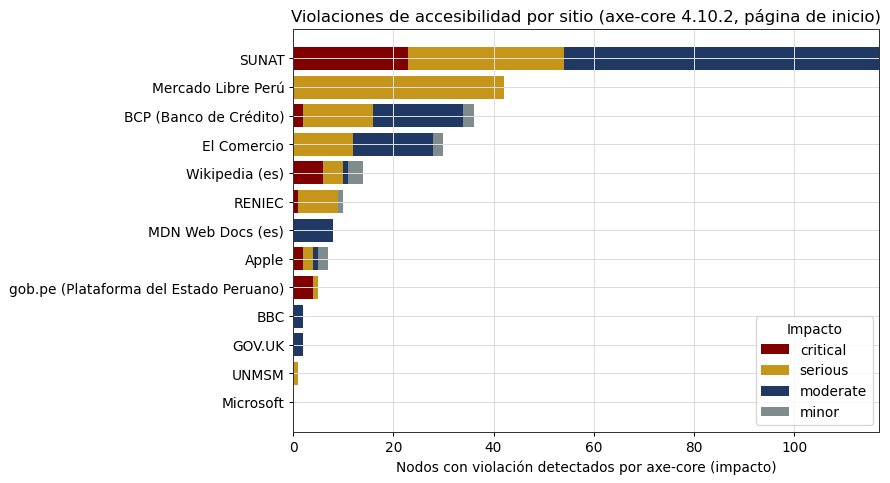

In [4]:
# =========================================================
# Celda 4 — Violaciones por sitio y por impacto (barras apiladas)
# =========================================================
ok = ok.sort_values("total_violaciones", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
izq = np.zeros(len(ok))
for col, color in [("critical", "#800000"), ("serious", "#C5961A"), ("moderate", "#1F3864"), ("minor", "#7F8C8D")]:
    ax.barh(ok.sitio, ok[col], left=izq, label=col, color=color); izq += ok[col].values
ax.set_xlabel("Nodos con violación detectados por axe-core (impacto)"); ax.set_title("Violaciones de accesibilidad por sitio (axe-core 4.10.2, página de inicio)")
ax.legend(title="Impacto"); plt.tight_layout(); plt.show()

In [5]:
# =========================================================
# Celda 5 — Perú frente a internacional (DESCRIPTIVO: n pequeño, sin pruebas de hipótesis)
# =========================================================
g = ok.groupby("pais").agg(sitios=("sitio", "count"), mediana_violaciones=("total_violaciones", "median"), media_violaciones=("total_violaciones", "mean"),
                           mediana_criticas_serias=("serious", "median"), con_lang=("lang", lambda s: (s != "(vacío)").sum()))
print(g.round(1).to_string())
print("\nLectura: con pocos sitios por grupo, la diferencia observada describe esta muestra y esta fecha; no se generaliza a 'Perú' ni a 'el mundo'.")

      sitios  mediana_violaciones  media_violaciones  mediana_criticas_serias  con_lang
pais                                                                                   
INT        6                  4.5                5.5                      0.0         6
PE         7                 30.0               34.4                     12.0         6

Lectura: con pocos sitios por grupo, la diferencia observada describe esta muestra y esta fecha; no se generaliza a 'Perú' ni a 'el mundo'.


                                                                                                                 sitios  nodos
regla                descripcion                                                                                              
region               All page content should be contained by landmarks                                                7     89
color-contrast       Elements must meet minimum color contrast ratio thresholds                                       4     55
link-name            Links must have discernible text                                                                 4     27
landmark-unique      Landmarks should have a unique role or role/label/title (i.e. accessible name) combination       4      4
aria-allowed-attr    Elements must only use supported ARIA attributes                                                 3      7
aria-allowed-role    ARIA role should be appropriate for the element                                           

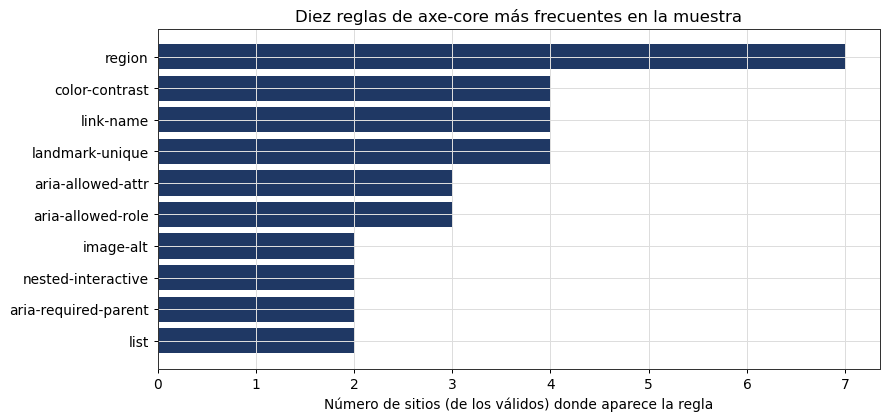

In [6]:
# =========================================================
# Celda 6 — Reglas más incumplidas (comparar con WebAIM Million)
# =========================================================
top = det.groupby(["regla", "descripcion"]).agg(sitios=("sitio", "nunique"), nodos=("nodos", "sum")).sort_values(["sitios", "nodos"], ascending=False).head(10)
print(top.to_string())
fig, ax = plt.subplots(figsize=(10, 4.8))
t = top.reset_index().iloc[::-1]
ax.barh(t.regla, t.sitios, color=PALETA[0]); ax.set_xlabel("Número de sitios (de los válidos) donde aparece la regla"); ax.set_title("Diez reglas de axe-core más frecuentes en la muestra")
plt.tight_layout(); plt.show()
print("\nCompare esta lista con las categorías de error más frecuentes del informe anual WebAIM Million (https://webaim.org/projects/million/): consulte las cifras vigentes allí; este cuaderno no las reproduce de memoria.")

## 3. Parte B — Verificador 12.2: formulario A frente a B (Fuente A)

AVISO: usando la PRUEBA TÉCNICA del bot (no se interpreta).
 id                                                          criterio formulario_A formulario_B
  1                               1.1.1 Contenido no textual: alt (A)    no cumple       cumple
  2                       1.3.1 / 3.3.2 Etiquetas e instrucciones (A)    no cumple       cumple
  3                                     3.1.1 Idioma de la página (A)       cumple       cumple
  4                                           2.4.7 Foco visible (AA)    no cumple       cumple
  5                   2.4.3 Orden del foco: sin tabindex positivo (A)    no cumple       cumple
  6                         2.5.8 Tamaño del objetivo ≥ 24×24 px (AA)    no cumple       cumple
  7                                       1.4.3 Contraste mínimo (AA)    no cumple       cumple
  8                    4.1.2 ARIA válido y referencias existentes (A)       cumple       cumple
  9                    1.3.1 / 2.4.6 Encabezados con jerarquía (A/AA)    no 

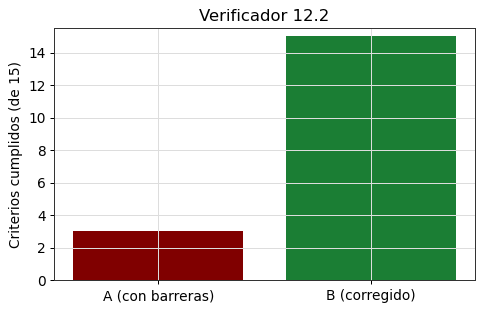

In [7]:
# =========================================================
# Celda 7 — Resultados del verificador de 15 criterios (CSV exportado por el ejercicio 12.2)
# =========================================================
arch = "ejercicio_12_2_verificador_resultados.csv"
if not os.path.exists(arch) and os.path.exists("ejercicio_12_2_verificador_PRUEBA_TECNICA_BOT.csv"):
    arch = "ejercicio_12_2_verificador_PRUEBA_TECNICA_BOT.csv"; print("AVISO: usando la PRUEBA TÉCNICA del bot (no se interpreta).")
if os.path.exists(arch):
    v = pd.read_csv(arch)
    v["A"] = v.formulario_A.eq("cumple"); v["B"] = v.formulario_B.eq("cumple")
    print(v[["id", "criterio", "formulario_A", "formulario_B"]].to_string(index=False))
    print(f"\nFormulario A cumple {v.A.sum()} de {len(v)} · Formulario B cumple {v.B.sum()} de {len(v)}")
    fig, ax = plt.subplots(figsize=(5.5, 3.6)); ax.bar(["A (con barreras)", "B (corregido)"], [v.A.sum(), v.B.sum()], color=[PALETA[1], PALETA[2]])
    ax.set_ylabel("Criterios cumplidos (de 15)"); ax.set_ylim(0, 15.5); ax.set_title("Verificador 12.2"); plt.tight_layout(); plt.show()
else:
    print("Falta el CSV del verificador. Ejecute el ejercicio 12.2, pulse «Exportar CSV» y súbalo. No se inventan datos.")

## 4. Parte C — Experimento «solo teclado» (Fuente D)

Diseño **intra-sujetos**: cada participante hace la **misma tarea** en A y en B, con **orden contrabalanceado**. Con **n ≥ 5** participantes se aplica la **prueba de Wilcoxon de rangos con signo** (apareada, no paramétrica); con menos, solo se describe.

- **Formato Markdown:** `W = min(W+, W−)`, donde `W+` es la suma de los rangos de las diferencias positivas `dᵢ = tiempo_Aᵢ − tiempo_Bᵢ` y `W−` la de las negativas.
- **Formato texto:** El estadístico W es el menor entre la suma de rangos de las diferencias positivas y la de las negativas.
- **Lectura verbal:** *Se ordenan las diferencias de tiempo por tamaño, se les asigna rango y se comprueba si los participantes tienden a ser más lentos con A que con B.*

AVISO: usando la PRUEBA TÉCNICA del bot (sus números NO se interpretan).
Participantes: 6 · filas: 12
            completadas  tiempo_mediana  tab_mediana  errores  seq_mediana
formulario                                                                
A                     0            0.26          5.0        0          3.0
B                     6            0.20          4.0        0          6.0

Wilcoxon apareado (tiempo A vs B), n = 6: W = 0.0, p = 0.0312
Recuerde: un tiempo de A mayor incluye tareas ABANDONADAS (no completadas); reporte también la tasa de completitud.


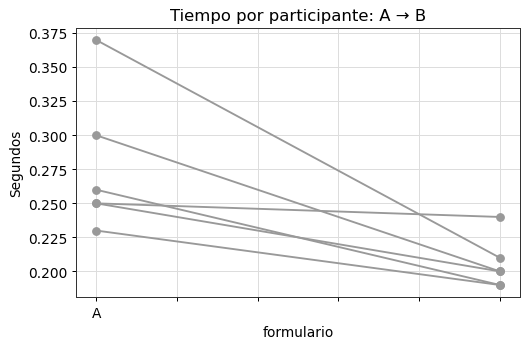

In [8]:
# =========================================================
# Celda 8 — Análisis apareado del experimento (tiempo, completitud, SEQ)
# =========================================================
arch = "ejercicio_12_3_experimento_teclado.csv"
if not os.path.exists(arch) and os.path.exists("ejercicio_12_3_experimento_PRUEBA_TECNICA_BOT.csv"):
    arch = "ejercicio_12_3_experimento_PRUEBA_TECNICA_BOT.csv"; print("AVISO: usando la PRUEBA TÉCNICA del bot (sus números NO se interpretan).")
if os.path.exists(arch):
    e = pd.read_csv(arch)
    print("Participantes:", e.participante.nunique(), "· filas:", len(e))
    print(e.groupby("formulario").agg(completadas=("resultado", lambda s: (s == "completada").sum()), tiempo_mediana=("segundos", "median"),
                                      tab_mediana=("pulsaciones_tab", "median"), errores=("errores_envio", "sum"), seq_mediana=("seq_1a7", "median")).round(2).to_string())
    ancho = e.pivot(index="participante", columns="formulario", values="segundos").dropna()
    n = len(ancho)
    if n >= 5:
        try:
            from scipy.stats import wilcoxon
            res = wilcoxon(ancho["A"], ancho["B"], zero_method="wilcox")
            print(f"\nWilcoxon apareado (tiempo A vs B), n = {n}: W = {res.statistic:.1f}, p = {res.pvalue:.4f}")
            print("Recuerde: un tiempo de A mayor incluye tareas ABANDONADAS (no completadas); reporte también la tasa de completitud.")
        except Exception as ex:
            print("No se pudo calcular Wilcoxon:", ex)
    else:
        print(f"\nn = {n} < 5: solo descripción; no se aplica Wilcoxon.")
    fig, ax = plt.subplots(figsize=(6, 4)); ancho.T.plot(ax=ax, legend=False, marker="o", color="#999999"); ax.set_ylabel("Segundos"); ax.set_title("Tiempo por participante: A → B"); plt.tight_layout(); plt.show()
else:
    print("Falta el CSV del experimento. Realice el ejercicio 12.3 con su equipo (mínimo 5 participantes) y súbalo. No se inventan datos.")

## 5. Conclusiones y declaración de uso de IA

- Las **pruebas automáticas** señalan dónde mirar; **no certifican** accesibilidad. Contraste, textos alternativos y etiquetas aparecen una y otra vez porque son **fáciles de medir** y **fáciles de olvidar**.
- El formulario **B** muestra que corregir es posible con **HTML semántico**: etiquetas, nombres, foco visible, objetivos de 24×24 px o más y mensajes de error asociados.
- La prueba **solo teclado** revela barreras que ninguna herramienta ve por completo (orden del foco, elementos no operables con teclado).
- **Declaración de uso de IA (guía v5 §16):** este cuaderno fue generado con asistencia de IA y **ejecutado y verificado** por el equipo docente (las fórmulas se comprueban con `assert`). La IA no recolectó datos de personas ni redactó hallazgos que no provinieran de una ejecución real.